# Week 1: Spatial econometrics foundations on US counties

**Author:** Dr. Ummara Razi  
Center for Sustainable Development and Green Innovation Research, Bahçeşehir Cyprus University, Nicosia, TRNC, Mersin 10, Turkey  
Institute of Energy Policy and Research (IEPRe), UNITEN Business School, Universiti Tenaga Nasional, Malaysia  
[Website](https://ummararazi.github.io) · [ORCID 0000-0002-5981-5736](https://orcid.org/0000-0002-5981-5736) · [LinkedIn](https://www.linkedin.com/in/dr-ummara-razi-45919752/)

**Goal:** learn the full spatial workflow on US counties, using free public data only.

**Note:** a *county* is a local administrative district inside a US state (similar to a district within a province), not a country. All data come from one country, the United States, divided into about 3,100 counties.

**What you will do**
1. Load county boundaries and ACS data (no API key needed).
2. Build three spatial weights matrices: Queen contiguity, k-nearest neighbours, inverse distance.
3. Test for spatial autocorrelation: global Moran's I and LISA cluster maps.
4. Run OLS with LM diagnostics (Anselin's decision rule).
5. Estimate SLX, SAR, SEM and SDM by maximum likelihood.
6. Compute direct, indirect (spillover) and total effects with simulated inference (LeSage & Pace, 2009).
7. Check robustness of the results to the choice of W.

**Practice model (cross-section, ACS 2018–2022):**
ln(median home value) = f( ln(median household income), ln(population density), share of homes heated by electricity )

This is a teaching model chosen for clarity, not a research claim. Later weeks extend the same code to panel data with fixed effects and to causal designs with spatial spillovers.

## 0. Install packages (run once)

In [1]:
# Uncomment and run once if packages are missing
# %pip install geopandas libpysal esda spreg mapclassify matplotlib requests scipy

In [2]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests
from scipy import stats, sparse

import libpysal
from libpysal.weights import Queen, KNN, DistanceBand
from libpysal.weights.util import attach_islands
import esda
import spreg

os.makedirs('outputs', exist_ok=True)
np.random.seed(42)
print('libpysal', libpysal.__version__, '| esda', esda.__version__, '| spreg', spreg.__version__)

libpysal 4.14.1 | esda 2.9.0 | spreg 1.9.0


## 1. Data

**Boundaries:** Census cartographic boundary file, counties 2020 (1:20m). We keep the contiguous 48 states plus DC, because Alaska, Hawaii and Puerto Rico have no land neighbours and would become isolated units in W.

**Attributes:** ACS 5-year 2022 from the Census API (keyless access allows a small number of requests per day, which is enough here).

| ACS code | Variable |
|---|---|
| B01003_001E | Total population |
| B19013_001E | Median household income |
| B25077_001E | Median home value |
| B25040_001E | Occupied units (house heating fuel total) |
| B25040_004E | Units heated by electricity |

In [3]:
SHP_URL = 'https://www2.census.gov/geo/tiger/GENZ2020/shp/cb_2020_us_county_20m.zip'
counties = gpd.read_file(SHP_URL)

drop_states = ['02', '15', '72']   # Alaska, Hawaii, Puerto Rico
counties = counties[~counties['STATEFP'].isin(drop_states)].copy()
counties = counties[['GEOID', 'STATEFP', 'NAME', 'ALAND', 'geometry']]
print('Counties in contiguous US + DC:', len(counties))

Counties in contiguous US + DC: 3108


### ⚠️ Before you run the next cell: get your free Census API key

The next cell downloads county data from the US Census Bureau. **Each user needs their own free API key.** Without one, the Census server often blocks requests (especially from Google Colab), and you will see an error such as `JSONDecodeError`.

**How to get your key (about 2 minutes, free):**

1. Go to https://api.census.gov/data/key_signup.html
2. Enter your organisation name and email address, then submit.
3. Open the email from the Census Bureau and click the **activation link**. The key will not work until it is activated.
4. Copy your key (a long string of letters and numbers).

**How to use it:**

In the next cell, paste your key between the quotes:

`CENSUS_KEY = 'paste-your-key-here'`

Then run the cell.



In [6]:
# Free Census API key (takes 2 minutes): https://api.census.gov/data/key_signup.html
# Paste it between the quotes. Without a key the API often refuses requests from
# Colab and other cloud servers and returns a web page instead of data.
CENSUS_KEY = ''

acs_vars = ['B01003_001E', 'B19013_001E', 'B25077_001E', 'B25040_001E', 'B25040_004E']
url = 'https://api.census.gov/data/2022/acs/acs5'
params = {'get': 'NAME,' + ','.join(acs_vars), 'for': 'county:*'}
if CENSUS_KEY:
    params['key'] = CENSUS_KEY.strip()
headers = {'User-Agent': 'Mozilla/5.0 (spatial-econometrics teaching notebook)'}

r = requests.get(url, params=params, headers=headers, timeout=60)
try:
    raw = r.json()
except ValueError:
    print('HTTP status:', r.status_code)
    print('The Census API did not return data. First part of the reply:')
    print(r.text[:400])
    if 'key' in r.text.lower() or r.status_code in (302, 403):
        print('Fix: request a free key at https://api.census.gov/data/key_signup.html, '
              'activate it from the email, paste it into CENSUS_KEY above and re-run.')
    raise

acs = pd.DataFrame(raw[1:], columns=raw[0])

for v in acs_vars:
    acs[v] = pd.to_numeric(acs[v], errors='coerce')
    acs.loc[acs[v] < 0, v] = np.nan   # Census uses large negative codes for missing

acs['GEOID'] = acs['state'] + acs['county']
acs = acs.rename(columns={'B01003_001E': 'pop', 'B19013_001E': 'income',
                          'B25077_001E': 'homevalue', 'B25040_001E': 'heat_total',
                          'B25040_004E': 'heat_elec'})
os.makedirs('outputs', exist_ok=True)
acs.to_csv('outputs/acs2022_county_raw.csv', index=False)
print(acs.shape)
acs.head()

(3222, 9)


,NAME,pop,income,homevalue,heat_total,heat_elec,state,county,GEOID
0,"Autauga County, Alabama",58761.0,68315.0,191800.0,22308.0,13327.0,01,001,01001
1,"Baldwin County, Alabama",233420.0,71039.0,266000.0,90802.0,79759.0,01,003,01003
2,"Barbour County, Alabama",24877.0,39712.0,102700.0,9016.0,7586.0,01,005,01005
3,"Bibb County, Alabama",22251.0,50669.0,120100.0,7216.0,4828.0,01,007,01007
4,"Blount County, Alabama",59077.0,57440.0,159800.0,21626.0,16144.0,01,009,01009


In [8]:
gdf = counties.merge(acs[['GEOID', 'pop', 'income', 'homevalue', 'heat_total', 'heat_elec']],
                     on='GEOID', how='left')

gdf['area_km2'] = gdf['ALAND'] / 1e6
gdf['ln_homevalue'] = np.log(gdf['homevalue'])
gdf['ln_income'] = np.log(gdf['income'])
gdf['ln_density'] = np.log(gdf['pop'] / gdf['area_km2'])
gdf['elec_heat_share'] = gdf['heat_elec'] / gdf['heat_total']

y_name = 'ln_homevalue'
x_names = ['ln_income', 'ln_density', 'elec_heat_share']

n_before = len(gdf)
gdf = gdf.replace([np.inf, -np.inf], np.nan).dropna(subset=[y_name] + x_names)
gdf = gdf.reset_index(drop=True)
print(f'Dropped {n_before - len(gdf)} counties with missing data; N = {len(gdf)}')

# Equal-area projection (metres) for distance-based weights and maps
gdf = gdf.to_crs(epsg=5070)
gdf[[y_name] + x_names].describe().T.round(3)

Dropped 11 counties with missing data; N = 3097


,count,mean,std,min,25%,50%,75%,max
ln_homevalue,3097.0,12.045,0.483,10.609,11.703,11.985,12.334,14.181
ln_income,3097.0,11.020,0.250,9.793,10.868,11.014,11.161,12.046
ln_density,3097.0,2.863,1.749,-2.519,1.883,2.856,3.820,10.242
elec_heat_share,3097.0,0.429,0.241,0.008,0.215,0.400,0.627,0.966


**Important:** after dropping rows you must build W on the final sample. A W built on a different set of units than your regression sample is one of the most common errors in submitted spatial papers.

## 2. Spatial weights matrices (W)

W defines who is a neighbour. It is an assumption you impose, so referees will ask you to justify it and to show results under alternatives.

- **Queen contiguity:** counties sharing a border or a corner. The standard baseline for administrative units.
- **k-nearest neighbours (k = 6):** every county gets exactly 6 neighbours, so there are no islands.
- **Inverse distance with a cut-off:** weight = 1 / distance between centroids, zero beyond a threshold (here 150 km). Useful when spillovers fade with distance, such as electricity markets or commuting zones.

All three are **row-standardised**, so Wy is the average of the neighbours' y.

In [9]:
# Queen contiguity
w_queen = Queen.from_dataframe(gdf, use_index=False)
print('Queen islands (no land neighbour):', w_queen.islands)

# Connect any islands to their nearest county so no unit has zero neighbours
if w_queen.islands:
    w_knn1 = KNN.from_dataframe(gdf, k=1)
    w_queen = attach_islands(w_queen, w_knn1)
    print('Islands after fix:', w_queen.islands)

# k-nearest neighbours (based on centroids)
w_knn6 = KNN.from_dataframe(gdf, k=6)

# Inverse distance, 150 km cut-off (projected units are metres)
cent = np.column_stack([gdf.geometry.centroid.x, gdf.geometry.centroid.y])
w_idist = DistanceBand(cent, threshold=150_000, binary=False, alpha=-1.0, silence_warnings=True)
if w_idist.islands:
    w_idist = attach_islands(w_idist, KNN(cent, k=1))

W = {'Queen': w_queen, 'KNN6': w_knn6, 'InvDist150km': w_idist}
for name, w in W.items():
    w.transform = 'r'
    print(f'{name:14s} N={w.n}  mean neighbours={w.mean_neighbors:.2f}  min={w.min_neighbors}  max={w.max_neighbors}')

/usr/local/lib/python3.13/dist-packages/libpysal/weights/contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 3 disconnected components.
 There are 2 islands with ids: 394, 1206.
  W.__init__(self, neighbors, ids=ids, **kw)
/usr/local/lib/python3.13/dist-packages/libpysal/weights/distance.py:153: UserWarning: The weights matrix is not fully connected: 
 There are 821 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


Queen islands (no land neighbour): [394, 1206]
Islands after fix: []
Queen          N=3097  mean neighbours=5.85  min=1  max=14
KNN6           N=3097  mean neighbours=6.00  min=6  max=6
InvDist150km   N=3097  mean neighbours=39.54  min=1  max=90


/usr/local/lib/python3.13/dist-packages/scipy/sparse/_data.py:128: RuntimeWarning: divide by zero encountered in reciprocal
  return self._with_data(data ** n)


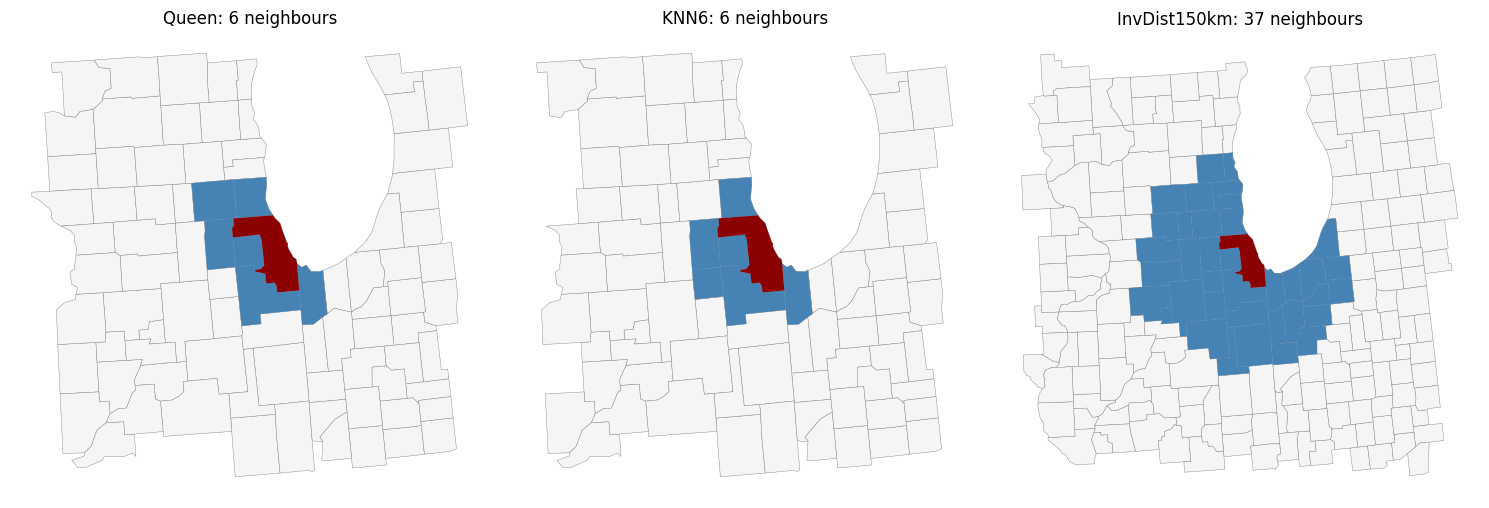

In [10]:
# Visual check: neighbours of one county (Cook County, IL = 17031, which contains Chicago)
focus = gdf.index[gdf['GEOID'] == '17031']
if len(focus):
    i = int(focus[0])
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, (name, w) in zip(axes, W.items()):
        nb = list(w.neighbors[i])
        sub = gdf.iloc[[i] + nb]
        gdf.cx[sub.total_bounds[0]-1e5:sub.total_bounds[2]+1e5,
               sub.total_bounds[1]-1e5:sub.total_bounds[3]+1e5].plot(ax=ax, color='whitesmoke', edgecolor='grey', lw=0.3)
        gdf.iloc[nb].plot(ax=ax, color='steelblue')
        gdf.iloc[[i]].plot(ax=ax, color='darkred')
        ax.set_title(f'{name}: {len(nb)} neighbours'); ax.axis('off')
    plt.tight_layout(); plt.savefig('outputs/fig_W_neighbours_cook.png', dpi=200); plt.show()

## 3. Exploratory spatial data analysis

### 3.1 Global Moran's I
Moran's I measures whether similar values cluster in space. I > 0 means clustering (high near high, low near low). Inference uses 999 random permutations of values across locations.

In [11]:
rows = []
for var in [y_name] + x_names:
    for wname, w in W.items():
        mi = esda.Moran(gdf[var].values, w, permutations=999)
        rows.append({'variable': var, 'W': wname, 'Moran_I': mi.I, 'E[I]': mi.EI,
                     'z': mi.z_sim, 'p_perm': mi.p_sim})
moran_tab = pd.DataFrame(rows)
moran_tab.to_csv('outputs/table_moran.csv', index=False)
moran_tab.round(4)

,variable,W,Moran_I,E[I],z,p_perm
0,ln_homevalue,Queen,0.7185,-0.0003,65.2070,0.001
1,ln_homevalue,KNN6,0.7204,-0.0003,68.5565,0.001
2,ln_homevalue,InvDist150km,0.6208,-0.0003,110.3413,0.001
3,ln_income,Queen,0.6128,-0.0003,57.0807,0.001
4,ln_income,KNN6,0.6026,-0.0003,59.6889,0.001
5,ln_income,InvDist150km,0.4889,-0.0003,87.3922,0.001
6,ln_density,Queen,0.6906,-0.0003,65.0753,0.001
7,ln_density,KNN6,0.6913,-0.0003,68.9002,0.001
8,ln_density,InvDist150km,0.6036,-0.0003,106.8678,0.001
9,elec_heat_share,Queen,0.8918,-0.0003,80.1499,0.001


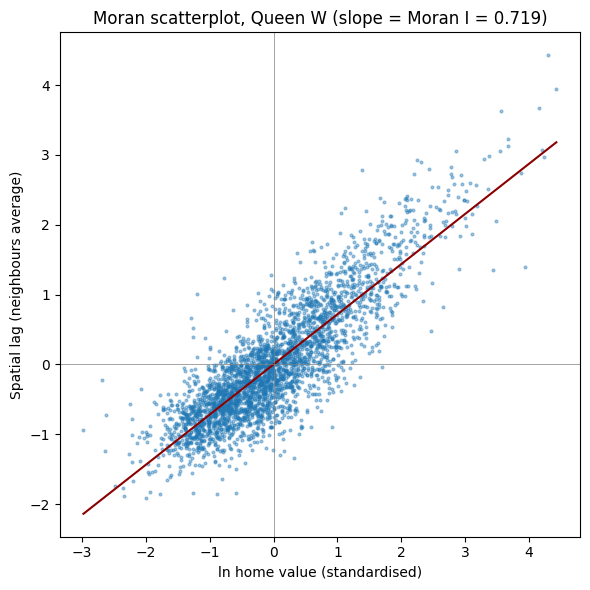

In [12]:
# Moran scatterplot: standardised y against its spatial lag
w = W['Queen']
z = (gdf[y_name] - gdf[y_name].mean()) / gdf[y_name].std()
wz = libpysal.weights.lag_spatial(w, z.values)
slope = np.polyfit(z, wz, 1)[0]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(z, wz, s=4, alpha=0.4)
xs = np.linspace(z.min(), z.max(), 50)
ax.plot(xs, slope * xs, color='darkred')
ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
ax.set_xlabel('ln home value (standardised)'); ax.set_ylabel('Spatial lag (neighbours average)')
ax.set_title(f'Moran scatterplot, Queen W (slope = Moran I = {slope:.3f})')
plt.tight_layout(); plt.savefig('outputs/fig_moran_scatter.png', dpi=200); plt.show()

### 3.2 Local Moran (LISA) cluster map
LISA decomposes global I into one statistic per county. Significant counties fall into four groups: High-High (hot spots), Low-Low (cold spots), and two outlier types (High-Low, Low-High).

With 3,000+ local tests some will be significant by chance. Report the map at p < 0.05 and check that the main clusters survive a stricter cut-off (e.g., p < 0.01), or a False Discovery Rate correction.

lisa_05
Not significant    1843
Low-Low             644
High-High           557
High-Low             36
Low-High             17
Name: count, dtype: int64


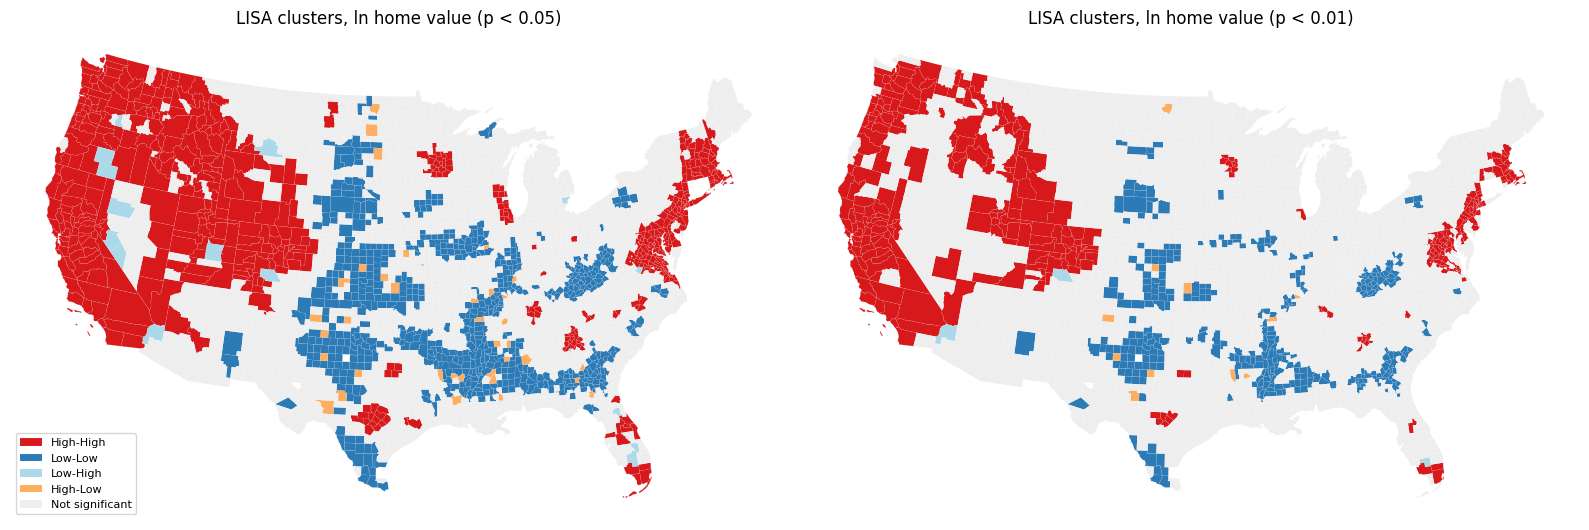

In [13]:
lisa = esda.Moran_Local(gdf[y_name].values, W['Queen'], permutations=999, seed=42)
labels = {1: 'High-High', 2: 'Low-High', 3: 'Low-Low', 4: 'High-Low'}

def lisa_class(lisa, alpha):
    return np.where(lisa.p_sim < alpha, pd.Series(lisa.q).map(labels), 'Not significant')

gdf['lisa_05'] = lisa_class(lisa, 0.05)
gdf['lisa_01'] = lisa_class(lisa, 0.01)
print(gdf['lisa_05'].value_counts())

colors = {'High-High': '#d7191c', 'Low-Low': '#2c7bb6', 'Low-High': '#abd9e9',
          'High-Low': '#fdae61', 'Not significant': '#eeeeee'}
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col, t in zip(axes, ['lisa_05', 'lisa_01'], ['p < 0.05', 'p < 0.01']):
    for cat, c in colors.items():
        sub = gdf[gdf[col] == cat]
        if len(sub):
            sub.plot(ax=ax, color=c, edgecolor='white', lw=0.05, label=cat)
    ax.set_title(f'LISA clusters, ln home value ({t})'); ax.axis('off')
axes[0].legend(loc='lower left', fontsize=8)
plt.tight_layout(); plt.savefig('outputs/fig_lisa_map.png', dpi=200); plt.show()

## 4. OLS and LM diagnostics

Start from OLS and test the residuals. Anselin's classic decision rule:
- Neither LM-lag nor LM-error significant: keep OLS.
- Only one significant: choose that model.
- Both significant: look at the **robust** versions (RLM-lag, RLM-error) and pick the larger/significant one.

Elhorst (2010, 2014) argues for a different route: start from the more general SDM and test down with LR tests (Section 5). Top journals now expect the Elhorst route, but reporting LM tests is still standard.

In [14]:
y = gdf[[y_name]].values
X = gdf[x_names].values

ols = spreg.OLS(y, X, w=W['Queen'], spat_diag=True, moran=True,
                name_y=y_name, name_x=x_names, name_w='Queen', name_ds='US counties')
print(ols.summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            : US counties
Weights matrix      :       Queen
Dependent Variable  :ln_homevalue                Number of Observations:        3097
Mean dependent var  :     12.0448                Number of Variables   :           4
S.D. dependent var  :      0.4826                Degrees of Freedom    :        3093
R-squared           :      0.6139
Adjusted R-squared  :      0.6135
Sum squared residual:      278.45                F-statistic           :   1639.0407
Sigma-square        :       0.090                Prob(F-statistic)     :           0
S.E. of regression  :       0.300                Log likelihood        :    -664.193
Sigma-square ML     :       0.090                Akaike info criterion :    1336.386
S.E of regression ML:      0.2998                Schwarz criterion     :    1360.539

-----------------

In [15]:
lm_rows = []
for wname, w in W.items():
    o = spreg.OLS(y, X, w=w, spat_diag=True, moran=True)
    lm_rows.append({'W': wname,
                    'Moran_resid': o.moran_res[0], 'p_Moran': o.moran_res[2],
                    'LM_lag': o.lm_lag[0], 'p_LM_lag': o.lm_lag[1],
                    'LM_error': o.lm_error[0], 'p_LM_error': o.lm_error[1],
                    'RLM_lag': o.rlm_lag[0], 'p_RLM_lag': o.rlm_lag[1],
                    'RLM_error': o.rlm_error[0], 'p_RLM_error': o.rlm_error[1]})
lm_tab = pd.DataFrame(lm_rows)
lm_tab.to_csv('outputs/table_LM_tests.csv', index=False)
lm_tab.round(4)

,W,Moran_resid,p_Moran,LM_lag,p_LM_lag,LM_error,p_LM_error,RLM_lag,p_RLM_lag,RLM_error,p_RLM_error
0,Queen,0.6552,0.0,2621.1135,0.0,3704.5224,0.0,110.1568,0.0,1193.5656,0.0
1,KNN6,0.6415,0.0,2776.6044,0.0,4064.3494,0.0,142.7528,0.0,1430.4978,0.0
2,InvDist150km,0.6028,0.0,4110.8930,0.0,11307.4571,0.0,155.1889,0.0,7351.7530,0.0


## 5. Spatial models: SLX, SAR, SEM, SDM

| Model | Equation | Spillovers come from |
|---|---|---|
| SLX | y = Xβ + WXθ + ε | Neighbours' X only (local, no feedback loop) |
| SAR (spatial lag) | y = ρWy + Xβ + ε | Neighbours' y (global, feedback loop) |
| SEM (spatial error) | y = Xβ + u, u = λWu + ε | Nothing: spatial correlation is a nuisance in the errors |
| SDM (spatial Durbin) | y = ρWy + Xβ + WXθ + ε | Neighbours' y and X |

SDM nests SAR (θ = 0), SLX (ρ = 0) and, via the common-factor restriction θ = −ρβ, SEM. That is why Elhorst recommends starting from SDM.

We build WX ourselves and pass it as extra regressors. This works with any spreg version and makes the model transparent.

In [16]:
def fit_all(y, X, w, x_names):
    WX = np.column_stack([libpysal.weights.lag_spatial(w, X[:, j]) for j in range(X.shape[1])])
    wx_names = ['W_' + n for n in x_names]
    XWX = np.hstack([X, WX])
    m = {}
    m['OLS'] = spreg.OLS(y, X, name_x=x_names)
    m['SLX'] = spreg.OLS(y, XWX, name_x=x_names + wx_names)
    m['SAR'] = spreg.ML_Lag(y, X, w=w, method='full', name_x=x_names)
    m['SEM'] = spreg.ML_Error(y, X, w=w, method='full', name_x=x_names)
    m['SDM'] = spreg.ML_Lag(y, XWX, w=w, method='full', name_x=x_names + wx_names)
    return m, WX

w = W['Queen']
models, WX = fit_all(y, X, w, x_names)
print(models['SDM'].summary)

ML_Lag


/usr/local/lib/python3.13/dist-packages/spreg/ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


ML_Error
ML_Lag
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :     dep_var                Number of Observations:        3097
Mean dependent var  :     12.0448                Number of Variables   :           8
S.D. dependent var  :      0.4826                Degrees of Freedom    :        3089
Pseudo R-squared    :      0.8698
Spatial Pseudo R-squared:  0.6433
Log likelihood      :    741.1708
Sigma-square ML     :      0.0306                Akaike info criterion :   -1466.342
S.E of regression   :      0.1750                Schwarz criterion     :   -1418.036

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
----------------------------

In [17]:
def coef_table(models):
    out = {}
    for name, m in models.items():
        names = list(m.name_x)
        b = np.asarray(m.betas).flatten()
        se = np.sqrt(np.diag(m.vm))
        if name in ('SAR', 'SDM'):
            names = names[:len(b) - 1] + ['rho']
        if name == 'SEM':
            names = names[:len(b) - 1] + ['lambda']
        p = 2 * (1 - stats.norm.cdf(np.abs(b / se)))
        star = np.where(p < 0.01, '***', np.where(p < 0.05, '**', np.where(p < 0.1, '*', '')))
        out[name] = pd.Series([f'{bi:.4f}{s} ({si:.4f})' for bi, si, s in zip(b, se, star)], index=names)
    tab = pd.DataFrame(out)
    ll = {k: getattr(m, 'logll', np.nan) for k, m in models.items()}
    aic = {k: getattr(m, 'aic', np.nan) for k, m in models.items()}
    tab.loc['Log-likelihood'] = pd.Series(ll).round(2)
    tab.loc['AIC'] = pd.Series(aic).round(2)
    return tab.fillna('')

coef_tab = coef_table(models)
coef_tab.to_csv('outputs/table_coefficients_queen.csv')
coef_tab

,OLS,SLX,SAR,SEM,SDM
CONSTANT,-3.1484*** (0.2732),-6.4804*** (0.3641),-4.4828*** (0.1838),0.6936*** (0.2218),-1.5208*** (0.2302)
W_elec_heat_share,,0.0732 (0.0723),,,-0.1578*** (0.0435)
W_ln_density,,-0.0411*** (0.0070),,,-0.0685*** (0.0042)
W_ln_income,,0.6155*** (0.0458),,,-0.6479*** (0.0333)
elec_heat_share,0.1426*** (0.0241),0.1839*** (0.0670),0.1522*** (0.0163),0.1683*** (0.0364),0.2120*** (0.0403)
lambda,,,,0.8383*** (0.0113),
ln_density,0.0519*** (0.0035),0.0693*** (0.0057),0.0243*** (0.0025),0.0763*** (0.0033),0.0741*** (0.0034)
ln_income,1.3597*** (0.0248),1.0481*** (0.0340),0.7789*** (0.0209),1.0031*** (0.0202),0.9850*** (0.0204)
rho,,,0.6483*** (0.0117),,0.8144*** (0.0122)
Log-likelihood,-664.19,-571.77,416.24,711.01,741.17


### 5.1 Testing down from SDM (likelihood-ratio tests)
- H0: θ = 0 (SDM reduces to SAR)
- H0: θ = −ρβ (SDM reduces to SEM, common-factor test)

If both are rejected, SDM is preferred.

In [18]:
k = len(x_names)
def lr(ll_u, ll_r, df):
    s = 2 * (ll_u - ll_r)
    return s, 1 - stats.chi2.cdf(s, df)

lr_sar = lr(models['SDM'].logll, models['SAR'].logll, k)
lr_sem = lr(models['SDM'].logll, models['SEM'].logll, k)
lr_tab = pd.DataFrame({'H0': ['SDM -> SAR (theta = 0)', 'SDM -> SEM (common factor)'],
                       'LR': [lr_sar[0], lr_sem[0]], 'df': [k, k],
                       'p': [lr_sar[1], lr_sem[1]]})
lr_tab.to_csv('outputs/table_LR_tests.csv', index=False)
lr_tab.round(4)

,H0,LR,df,p
0,SDM -> SAR (theta = 0),649.8600,3,0.0
1,SDM -> SEM (common factor),60.3266,3,0.0


## 6. Direct, indirect and total effects

**The most important lesson of the week:** in SAR and SDM, the coefficients β and θ are **not** marginal effects, because of the feedback loop through ρWy. A change in county i's income affects its neighbours' home values, which feed back to county i, and so on.

For SDM the effect matrix for regressor k is S_k = (I − ρW)⁻¹ (β_k I + θ_k W):
- **Direct effect** = average of the diagonal of S_k (own-county effect, including feedback)
- **Total effect** = average row sum = (β_k + θ_k) / (1 − ρ)
- **Indirect (spillover) effect** = total − direct

Inference: draw 1,000 parameter vectors from N(estimates, VCV) and recompute the effects each time (LeSage & Pace, 2009). Traces of powers of W are approximated with a fast Monte Carlo estimator, so this runs in seconds even for 3,000+ counties. Reporting SDM coefficients instead of these effects is a classic reason for rejection.

In [19]:
def w_power_traces(w, P=100, R=50, seed=42):
    """tr(W^p)/N for p = 0..P+1 (exact for p = 0, 1, 2; Monte Carlo for higher powers)."""
    Ws = w.sparse.tocsr()
    N = Ws.shape[0]
    rng = np.random.default_rng(seed)
    U = rng.choice([-1.0, 1.0], size=(N, R))
    tr = np.zeros(P + 2)
    tr[0] = N
    tr[1] = Ws.diagonal().sum()
    tr[2] = Ws.multiply(Ws.T).sum()
    V = Ws @ (Ws @ U)
    for p in range(3, P + 2):
        V = Ws @ V
        tr[p] = np.mean(np.sum(U * V, axis=0))
    return tr / N

def sdm_effects(rho, beta, theta, trN):
    P = len(trN) - 2
    powers = rho ** np.arange(P + 1)
    direct = beta * np.sum(powers * trN[:P + 1]) + theta * np.sum(powers * trN[1:P + 2])
    total = (beta + theta) / (1 - rho)
    return direct, total - direct, total

def effects_table(model, x_names, w, n_draws=1000, sdm=True, seed=42):
    trN = w_power_traces(w)
    b = np.asarray(model.betas).flatten()
    V = np.asarray(model.vm)
    k = len(x_names)
    rng = np.random.default_rng(seed)
    draws = rng.multivariate_normal(b, V, size=n_draws)
    draws = draws[np.abs(draws[:, -1]) < 1]   # keep stable rho draws
    rows = []
    for j, name in enumerate(x_names):
        sims = []
        for d in draws:
            rho = d[-1]
            beta = d[1 + j]
            theta = d[1 + k + j] if sdm else 0.0
            sims.append(sdm_effects(rho, beta, theta, trN))
        sims = np.array(sims)
        point = sdm_effects(b[-1], b[1 + j], b[1 + k + j] if sdm else 0.0, trN)
        for e, lab in enumerate(['Direct', 'Indirect', 'Total']):
            s = sims[:, e]
            se = s.std()
            zstat = point[e] / se
            rows.append({'variable': name, 'effect': lab, 'estimate': point[e], 'se': se,
                         'z': zstat, 'p': 2 * (1 - stats.norm.cdf(abs(zstat))),
                         'ci_2.5': np.percentile(s, 2.5), 'ci_97.5': np.percentile(s, 97.5)})
    return pd.DataFrame(rows)

eff_sdm = effects_table(models['SDM'], x_names, W['Queen'], sdm=True)
eff_sdm.to_csv('outputs/table_effects_SDM_queen.csv', index=False)
eff_sdm.round(4)

,variable,effect,estimate,se,z,p,ci_2.5,ci_97.5
0,ln_income,Direct,1.0308,0.0207,49.7417,0.0000,0.9909,1.0697
1,ln_income,Indirect,0.7861,0.1025,7.6686,0.0000,0.5959,1.0025
2,ln_income,Total,1.8169,0.1064,17.0702,0.0000,1.6163,2.0486
3,ln_density,Direct,0.0717,0.0034,21.2609,0.0000,0.0654,0.0781
4,ln_density,Indirect,-0.0416,0.0132,-3.1450,0.0017,-0.0671,-0.0149
5,ln_density,Total,0.0300,0.0136,2.2110,0.0270,0.0041,0.0565
6,elec_heat_share,Direct,0.2164,0.0374,5.7922,0.0000,0.1413,0.2930
7,elec_heat_share,Indirect,0.0758,0.0904,0.8391,0.4014,-0.0953,0.2588
8,elec_heat_share,Total,0.2922,0.0853,3.4268,0.0006,0.1166,0.4656


In [22]:
# Sanity check against an exact dense calculation (feasible for N around 3,000)
Wd = W['Queen'].full()[0]
b = np.asarray(models['SDM'].betas).flatten(); rho = b[-1]; k = len(x_names)
Sinv = np.linalg.inv(np.eye(Wd.shape[0]) - rho * Wd)
for j, name in enumerate(x_names):
    S = Sinv @ (b[1 + j] * np.eye(Wd.shape[0]) + b[1 + k + j] * Wd)
    d = np.trace(S) / S.shape[0]; t = S.sum() / S.shape[0]
    print(f'{name:16s} exact direct={d:.4f} indirect={t - d:.4f} total={t:.4f}')
del Wd, Sinv, S

ln_income        exact direct=1.0312 indirect=0.7857 total=1.8169
ln_density       exact direct=0.0717 indirect=-0.0416 total=0.0300
elec_heat_share  exact direct=0.2164 indirect=0.0758 total=0.2922


## 7. Robustness to the choice of W

Referees in Energy Economics, JEEM and RSUE routinely ask for this. If the sign and rough size of the indirect effects hold across W, say so; if they do not, that is a finding you must discuss, not hide.

In [23]:
rob = []
for wname, w in W.items():
    m, _ = fit_all(y, X, w, x_names)
    e = effects_table(m['SDM'], x_names, w, sdm=True)
    e['W'] = wname
    e['rho'] = np.asarray(m['SDM'].betas).flatten()[-1]
    e['AIC_SDM'] = m['SDM'].aic
    rob.append(e)
rob = pd.concat(rob)
rob['cell'] = rob.apply(lambda r: f"{r.estimate:.4f}{'***' if r.p < 0.01 else '**' if r.p < 0.05 else '*' if r.p < 0.1 else ''}", axis=1)
rob_wide = rob.pivot_table(index=['variable', 'effect'], columns='W', values='cell', aggfunc='first')
rob_wide.to_csv('outputs/table_effects_by_W.csv')
print(rob.groupby('W')[['rho', 'AIC_SDM']].first().round(4))
rob_wide

ML_Lag


/usr/local/lib/python3.13/dist-packages/spreg/ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


ML_Error
ML_Lag
ML_Lag


/usr/local/lib/python3.13/dist-packages/spreg/ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


ML_Error
ML_Lag
ML_Lag


/usr/local/lib/python3.13/dist-packages/spreg/ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


ML_Error
ML_Lag
                 rho    AIC_SDM
W                              
InvDist150km  0.9203 -1633.4124
KNN6          0.8180 -1393.9868
Queen         0.8144 -1466.3416


W                        InvDist150km        KNN6       Queen
variable        effect                                       
elec_heat_share Direct      0.1879***   0.2109***   0.2164***
                Indirect     0.4917**      0.1380      0.0758
                Total       0.6796***   0.3489***   0.2922***
ln_density      Direct      0.0717***   0.0680***   0.0717***
                Indirect      -0.0522  -0.0427***  -0.0416***
                Total          0.0195     0.0252*    0.0300**
ln_income       Direct      1.0508***   1.0377***   1.0308***
                Indirect    1.5249***   0.7932***   0.7861***
                Total       2.5757***   1.8309***   1.8169***

## 8. What to take away, and the referee's objection

**Reading your results**
- ρ tells you how strongly home values move with neighbours' home values, after controls.
- Indirect effects are often as large as, or larger than, direct effects. That is the economic content a spatial paper adds.
- Compare SDM AIC across W: lower is a better fit, but fit alone does not justify W. Your economic story should.

**The Gibbons & Overman (2012) critique**
They argue that SAR/SDM coefficients are identified only by functional form, because Wy is endogenous and WX, W²X are weak instruments. This cross-section is a good example: ρ here captures sorting, shared amenities and omitted regional factors, not a causal spillover. Applied work answers this by:
1. Using panel data with county and year fixed effects.
2. Using a credible source of variation, such as a policy or shock that hits some places and not others, with spillovers measured in distance rings around treated areas.
3. Treating SDM as a complement to the causal design, not the identification strategy.

**Exercises before Week 2**
1. Change k in KNN to 4 and 10, and the distance cut-off to 100 km and 250 km. Which results move?
2. Add state fixed effects (state dummies) to X. What happens to ρ? Why?
3. Re-estimate SAR by GMM with `spreg.GM_Lag` and compare ρ with the ML estimate.
4. Write one paragraph, in the style of a methods section, justifying your preferred W for a spillover question of your choice.

In [24]:
# Save the analysis sample (with geometry) for Week 2
gdf.to_file('outputs/county_sample_week1.gpkg', driver='GPKG')
print('Saved files:')
for f in sorted(os.listdir('outputs')):
    print(' -', f)

Saved files:
 - acs2022_county_raw.csv
 - county_sample_week1.gpkg
 - fig_W_neighbours_cook.png
 - fig_lisa_map.png
 - fig_moran_scatter.png
 - table_LM_tests.csv
 - table_LR_tests.csv
 - table_coefficients_queen.csv
 - table_effects_SDM_queen.csv
 - table_effects_by_W.csv
 - table_moran.csv


## Key references
- Anselin, L. (1988). *Spatial Econometrics: Methods and Models*. Kluwer.
- LeSage, J. & Pace, R.K. (2009). *Introduction to Spatial Econometrics*. CRC Press.
- Elhorst, J.P. (2014). *Spatial Econometrics: From Cross-Sectional Data to Spatial Panels*. Springer.
- Halleck Vega, S. & Elhorst, J.P. (2015). The SLX model. *Journal of Regional Science*, 55(3), 339–363.
- Gibbons, S. & Overman, H. (2012). Mostly pointless spatial econometrics? *Journal of Regional Science*, 52(2), 172–191.
- Rey, S., Arribas-Bel, D. & Wolf, L. *Geographic Data Science with Python* (free online book).

## How to cite

If you use or adapt this notebook, please cite:

> Razi, U. (2026). *Spatial Econometrics in Python: US Counties* [Computer software and teaching materials]. GitHub. ORCID: https://orcid.org/0000-0002-5981-5736

© 2026 Ummara Razi. Released under the MIT licence; please keep this attribution when reusing or adapting the code.

In [25]:
# Download all outputs (tables, maps, cleaned data) as one zip file
import os, shutil

print('Files in outputs/:')
for f in sorted(os.listdir('outputs')):
    size_kb = os.path.getsize(os.path.join('outputs', f)) / 1024
    print(f'  {f:45s} {size_kb:8.1f} KB')

zip_path = shutil.make_archive('Week1_outputs', 'zip', 'outputs')
print('\nCreated:', zip_path)

try:
    from google.colab import files   # works only on Colab
    files.download(zip_path)
    print('Download started. Check your browser downloads.')
except ImportError:
    print('Running locally: the zip is saved next to this notebook.')

Files in outputs/:
  acs2022_county_raw.csv                           251.1 KB
  county_sample_week1.gpkg                        1712.0 KB
  fig_W_neighbours_cook.png                        362.5 KB
  fig_lisa_map.png                                 590.9 KB
  fig_moran_scatter.png                            232.6 KB
  table_LM_tests.csv                                 0.5 KB
  table_LR_tests.csv                                 0.1 KB
  table_coefficients_queen.csv                       0.8 KB
  table_effects_SDM_queen.csv                        1.2 KB
  table_effects_by_W.csv                             0.5 KB
  table_moran.csv                                    1.1 KB

Created: /content/Week1_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started. Check your browser downloads.
